# IPL Deliveries: Data Inspection and Cleaning

**Author:** Aditya Jha

This is the first stage of my IPL ball-by-ball analysis project. Before I do any analysis I want to know what the data actually looks like, whether I can trust it, and what needs fixing.

**What I do in this notebook**
1. Load the data and take a first look
2. Check data quality (missing values, duplicates, data types)
3. Validate the key columns (innings, overs, runs, wickets, teams)
4. Clean the data
5. Run a few sanity checks on the cleaned data
6. Save a clean file for the next stage

**Next stage:** load the clean file into a SQL database to answer questions, then build a Power BI dashboard on top of it.

#1.setup

In [103]:
import pandas as pd
import matplotlib.pyplot as plt

## 2. Loading the data


In [ ]:
df = pd.read_csv("/content/ipl_deliveries_ipl_deliveries.csv")
print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns")

Loaded 30,563 rows and 19 columns


In [105]:
# Working on a separate copy
df_clean = df.copy()

## 3. First look


In [106]:
df_clean.head()

,ID,Team,innings,overs,ballnumber,batter,bowler,non-striker,extra_type,batsman_run,extras_run,total_run,non_boundary,isWicketDelivery,player_out,kind,fielders_involved,BattingTeam,BowlingTeam
0,1312200,Rajasthan RoyalsGujarat Titans,1.0,0.0,1.0,YBK Jaiswal,Mohammed Shami,JC Buttler,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,Rajasthan Royals,Gujarat Titans
1,1312200,Rajasthan RoyalsGujarat Titans,1.0,0.0,2.0,YBK Jaiswal,Mohammed Shami,JC Buttler,legbyes,0.0,1.0,1.0,0.0,0.0,NaN,NaN,NaN,Rajasthan Royals,Gujarat Titans
2,1312200,Rajasthan RoyalsGujarat Titans,1.0,0.0,3.0,JC Buttler,Mohammed Shami,YBK Jaiswal,NaN,1.0,0.0,1.0,0.0,0.0,NaN,NaN,NaN,Rajasthan Royals,Gujarat Titans
3,1312200,Rajasthan RoyalsGujarat Titans,1.0,0.0,4.0,YBK Jaiswal,Mohammed Shami,JC Buttler,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,Rajasthan Royals,Gujarat Titans
4,1312200,Rajasthan RoyalsGujarat Titans,1.0,0.0,5.0,YBK Jaiswal,Mohammed Shami,JC Buttler,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,Rajasthan Royals,Gujarat Titans


In [107]:
df_clean.sample()

,ID,Team,innings,overs,ballnumber,batter,bowler,non-striker,extra_type,batsman_run,extras_run,total_run,non_boundary,isWicketDelivery,player_out,kind,fielders_involved,BattingTeam,BowlingTeam
14991,1304058,Lucknow Super GiantsSunrisers Hyderabad,1.0,0.0,2.0,KL Rahul,B Kumar,Q de Kock,NaN,1.0,0.0,1.0,0.0,0.0,NaN,NaN,NaN,Lucknow Super Giants,Sunrisers Hyderabad


In [108]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30563 entries, 0 to 30562
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ID                 30563 non-null  int64  
 1   Team               30562 non-null  object 
 2   innings            30562 non-null  float64
 3   overs              30562 non-null  float64
 4   ballnumber         30562 non-null  float64
 5   batter             30562 non-null  object 
 6   bowler             30562 non-null  object 
 7   non-striker        30562 non-null  object 
 8   extra_type         1717 non-null   object 
 9   batsman_run        30562 non-null  float64
 10  extras_run         30562 non-null  float64
 11  total_run          30562 non-null  float64
 12  non_boundary       30562 non-null  float64
 13  isWicketDelivery   30562 non-null  float64
 14  player_out         1526 non-null   object 
 15  kind               1526 non-null   object 
 16  fielders_involved  113

In [109]:
df_clean.columns

Index(['ID', 'Team', 'innings', 'overs', 'ballnumber', 'batter', 'bowler',
       'non-striker', 'extra_type', 'batsman_run', 'extras_run', 'total_run',
       'non_boundary', 'isWicketDelivery', 'player_out', 'kind',
       'fielders_involved', 'BattingTeam', 'BowlingTeam'],
      dtype='object')

In [110]:
df_clean.describe()

,ID,innings,overs,ballnumber,batsman_run,extras_run,total_run,non_boundary,isWicketDelivery
count,3.056300e+04,30562.000000,30562.000000,30562.000000,30562.000000,30562.000000,30562.000000,30562.000000,30562.000000
mean,1.283607e+06,1.482887,9.264479,3.641679,1.258164,0.070120,1.328283,0.000098,0.049931
std,2.594083e+04,0.501284,5.687962,1.829457,1.658710,0.350608,1.645979,0.009907,0.217807
min,1.000000e+00,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.254097e+06,1.000000,4.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.304057e+06,1.000000,9.000000,4.000000,1.000000,0.000000,1.000000,0.000000,0.000000
75%,1.304089e+06,2.000000,14.000000,5.000000,1.000000,0.000000,1.000000,0.000000,0.000000
max,1.312200e+06,4.000000,19.000000,10.000000,6.000000,5.000000,7.000000,1.000000,1.000000


## 4. Data quality checks
### 4.1 Missing values


In [111]:
missing = df_clean.isnull().sum()
missing

,0
ID,0
Team,1
innings,1
overs,1
ballnumber,1
batter,1
bowler,1
non-striker,1
extra_type,28846
batsman_run,1


In [112]:
missing_report = pd.DataFrame({
    "missing": missing,
    "percent": (missing / len(df_clean) * 100).round(2)
})

In [113]:
missing_report = missing_report[missing_report["missing"] > 0]

In [114]:
if missing_report.empty:
    print("No missing values in any column.")
else:
    display(missing_report.sort_values("missing", ascending=False))

,missing,percent
fielders_involved,29432,96.30
player_out,29037,95.01
kind,29037,95.01
extra_type,28846,94.38
innings,1,0.00
Team,1,0.00
bowler,1,0.00
overs,1,0.00
batter,1,0.00
ballnumber,1,0.00


In ball-by-ball data some columns are empty on purpose (for example, the dismissed player on a delivery with no wicket). So a missing value is only a problem if it shows up where a value should always exist.


In [115]:
dup_count = df_clean.duplicated().sum()
print("Exact duplicate rows:", dup_count)

Exact duplicate rows: 0


### 4.3 Data types


In [116]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30563 entries, 0 to 30562
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ID                 30563 non-null  int64  
 1   Team               30562 non-null  object 
 2   innings            30562 non-null  float64
 3   overs              30562 non-null  float64
 4   ballnumber         30562 non-null  float64
 5   batter             30562 non-null  object 
 6   bowler             30562 non-null  object 
 7   non-striker        30562 non-null  object 
 8   extra_type         1717 non-null   object 
 9   batsman_run        30562 non-null  float64
 10  extras_run         30562 non-null  float64
 11  total_run          30562 non-null  float64
 12  non_boundary       30562 non-null  float64
 13  isWicketDelivery   30562 non-null  float64
 14  player_out         1526 non-null   object 
 15  kind               1526 non-null   object 
 16  fielders_involved  113

## 5. Checking the key columns
### 5.1 Innings, overs and ball numbers



In [117]:
print("Innings distribution (number of deliveries):")
print(df_clean["innings"].value_counts().sort_index())

Innings distribution (number of deliveries):
innings
1.0    15822
2.0    14728
3.0        6
4.0        6
Name: count, dtype: int64


In [118]:
for col in ["innings", "overs", "ballnumber"]:
    print(f"{col}: min = {df_clean[col].min()}, max = {df_clean[col].max()}, unique values = {df_clean[col].nunique()}")

innings: min = 1.0, max = 4.0, unique values = 4
overs: min = 0.0, max = 19.0, unique values = 20
ballnumber: min = 1.0, max = 10.0, unique values = 10


A T20 innings has 20 overs. Ball numbers can go past 6 within an over because wides and no-balls are bowled again, so a high maximum there is not automatically an error.


In [119]:
run_mismatch = (df_clean["batsman_run"] + df_clean["extras_run"]) != df_clean["total_run"]
print("Deliveries where the runs do not add up:", run_mismatch.sum())

Deliveries where the runs do not add up: 1


In [120]:
df_clean[(df_clean["batsman_run"] + df_clean["extras_run"]) !=df_clean["total_run"]]

,ID,Team,innings,overs,ballnumber,batter,bowler,non-striker,extra_type,batsman_run,extras_run,total_run,non_boundary,isWicketDelivery,player_out,kind,fielders_involved,BattingTeam,BowlingTeam
30562,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


i found a bug where nan values row is found so droping nan values row

In [121]:
df_clean= df.drop(index=30562)

In [122]:
run_mismatch = (df_clean["batsman_run"] + df_clean["extras_run"]) != df_clean["total_run"]
print("Deliveries where the runs do not add up:", run_mismatch.sum())

Deliveries where the runs do not add up: 0


In [123]:
### 5.3 Wicket flag
print("isWicketDelivery values:")
print(df_clean["isWicketDelivery"].value_counts(dropna=False))

isWicketDelivery values:
isWicketDelivery
0.0    29036
1.0     1526
Name: count, dtype: int64


In [124]:
valid_flags = df_clean["isWicketDelivery"].dropna().isin([0, 1]).all()
print("Wicket flag contains only 0 and 1:", valid_flags)

Wicket flag contains only 0 and 1: True


### 5.4 Non-boundary flag


In [125]:
print("non_boundary values:")
print(df_clean["non_boundary"].value_counts(dropna=False))

non_boundary values:
non_boundary
0.0    30559
1.0        3
Name: count, dtype: int64


### 5.5 Team names


In [126]:
team_cols = [c for c in ["BattingTeam", "BowlingTeam"] if c in df_clean.columns]


In [127]:
for col in team_cols:
    print(f"{col}: {df_clean[col].nunique()} unique names")
    for name in sorted(df_clean[col].dropna().unique()):
        print("  -", repr(name))
    print()

BattingTeam: 10 unique names
  - 'Chennai Super Kings'
  - 'Delhi Capitals'
  - 'Gujarat Titans'
  - 'Kolkata Knight Riders'
  - 'Lucknow Super Giants'
  - 'Mumbai Indians'
  - 'Punjab Kings'
  - 'Rajasthan Royals'
  - 'Royal Challengers Bangalore'
  - 'Sunrisers Hyderabad'

BowlingTeam: 10 unique names
  - 'Chennai Super Kings'
  - 'Delhi Capitals'
  - 'Gujarat Titans'
  - 'Kolkata Knight Riders'
  - 'Lucknow Super Giants'
  - 'Mumbai Indians'
  - 'Punjab Kings'
  - 'Rajasthan Royals'
  - 'Royal Challengers Bangalore'
  - 'Sunrisers Hyderabad'



IPL franchises have been renamed over the years (Delhi Daredevils became Delhi Capitals, Kings XI Punjab became Punjab Kings, and so on). If both the old and the new name appear above, they need to be merged, otherwise one team will be counted as two when I group in SQL and Power BI.


## 6. Cleaning
- I work on a copy so the original data stays untouched.


### 6.1 Remove stray spaces from column names and text values

In [128]:
df_clean.columns = df_clean.columns.str.strip()
df_clean

,ID,Team,innings,overs,ballnumber,batter,bowler,non-striker,extra_type,batsman_run,extras_run,total_run,non_boundary,isWicketDelivery,player_out,kind,fielders_involved,BattingTeam,BowlingTeam
0,1312200,Rajasthan RoyalsGujarat Titans,1.0,0.0,1.0,YBK Jaiswal,Mohammed Shami,JC Buttler,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,Rajasthan Royals,Gujarat Titans
1,1312200,Rajasthan RoyalsGujarat Titans,1.0,0.0,2.0,YBK Jaiswal,Mohammed Shami,JC Buttler,legbyes,0.0,1.0,1.0,0.0,0.0,NaN,NaN,NaN,Rajasthan Royals,Gujarat Titans
2,1312200,Rajasthan RoyalsGujarat Titans,1.0,0.0,3.0,JC Buttler,Mohammed Shami,YBK Jaiswal,NaN,1.0,0.0,1.0,0.0,0.0,NaN,NaN,NaN,Rajasthan Royals,Gujarat Titans
3,1312200,Rajasthan RoyalsGujarat Titans,1.0,0.0,4.0,YBK Jaiswal,Mohammed Shami,JC Buttler,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,Rajasthan Royals,Gujarat Titans
4,1312200,Rajasthan RoyalsGujarat Titans,1.0,0.0,5.0,YBK Jaiswal,Mohammed Shami,JC Buttler,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,Rajasthan Royals,Gujarat Titans
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30557,1254065,Punjab KingsChennai Super Kings,2.0,7.0,6.0,F du Plessis,M Ashwin,MM Ali,NaN,2.0,0.0,2.0,0.0,0.0,NaN,NaN,NaN,Chennai Super Kings,Punjab Kings
30558,1254065,Punjab KingsChennai Super Kings,2.0,8.0,1.0,MM Ali,RP Meredith,F du Plessis,NaN,4.0,0.0,4.0,0.0,0.0,NaN,NaN,NaN,Chennai Super Kings,Punjab Kings
30559,1254065,Punjab KingsChennai Super Kings,2.0,8.0,2.0,MM Ali,RP Meredith,F du Plessis,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,Chennai Super Kings,Punjab Kings
30560,1254065,Punjab KingsChennai Super Kings,2.0,8.0,3.0,MM Ali,RP Meredith,F du Plessis,NaN,1.0,0.0,1.0,0.0,0.0,NaN,NaN,NaN,Chennai Super Kings,Punjab Kings


### 6.2 Remove duplicate rows

In [129]:

before = len(df_clean)
df_clean = df_clean.drop_duplicates()
print(f"Rows before: {before:,}")
print(f"Rows after:  {len(df_clean):,}")
print(f"Removed:     {before - len(df_clean):,}")

Rows before: 30,562
Rows after:  30,562
Removed:     0


## 7. Checking the cleaned data


In [130]:
print(f"Original data: {df.shape[0]:,} rows, {df.shape[1]} columns")
print(f"Cleaned data:  {df_clean.shape[0]:,} rows, {df_clean.shape[1]} columns")
print()
print("Duplicate rows left:", df_clean.duplicated().sum())
print("Total missing values (original):", df.isnull().sum().sum())
print("Total missing values (cleaned): ", df_clean.isnull().sum().sum())

Original data: 30,563 rows, 19 columns
Cleaned data:  30,562 rows, 19 columns

Duplicate rows left: 0
Total missing values (original): 116366
Total missing values (cleaned):  116348


In [131]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30563 entries, 0 to 30562
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ID                 30563 non-null  int64  
 1   Team               30562 non-null  object 
 2   innings            30562 non-null  float64
 3   overs              30562 non-null  float64
 4   ballnumber         30562 non-null  float64
 5   batter             30562 non-null  object 
 6   bowler             30562 non-null  object 
 7   non-striker        30562 non-null  object 
 8   extra_type         1717 non-null   object 
 9   batsman_run        30562 non-null  float64
 10  extras_run         30562 non-null  float64
 11  total_run          30562 non-null  float64
 12  non_boundary       30562 non-null  float64
 13  isWicketDelivery   30562 non-null  float64
 14  player_out         1526 non-null   object 
 15  kind               1526 non-null   object 
 16  fielders_involved  113

In [132]:
numeric_cols = [
    "innings", "overs", "ballnumber",
    "batsman_run", "extras_run", "total_run",
    "non_boundary", "isWicketDelivery"
]
print("Missing values in the key numeric columns:")
print(df_clean[numeric_cols].isna().sum())

Missing values in the key numeric columns:
innings             0
overs               0
ballnumber          0
batsman_run         0
extras_run          0
total_run           0
non_boundary        0
isWicketDelivery    0
dtype: int64


In [133]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30562 entries, 0 to 30561
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ID                 30562 non-null  int64  
 1   Team               30562 non-null  object 
 2   innings            30562 non-null  float64
 3   overs              30562 non-null  float64
 4   ballnumber         30562 non-null  float64
 5   batter             30562 non-null  object 
 6   bowler             30562 non-null  object 
 7   non-striker        30562 non-null  object 
 8   extra_type         1717 non-null   object 
 9   batsman_run        30562 non-null  float64
 10  extras_run         30562 non-null  float64
 11  total_run          30562 non-null  float64
 12  non_boundary       30562 non-null  float64
 13  isWicketDelivery   30562 non-null  float64
 14  player_out         1526 non-null   object 
 15  kind               1526 non-null   object 
 16  fielders_involved  113

## 8. Quick sanity checks with charts


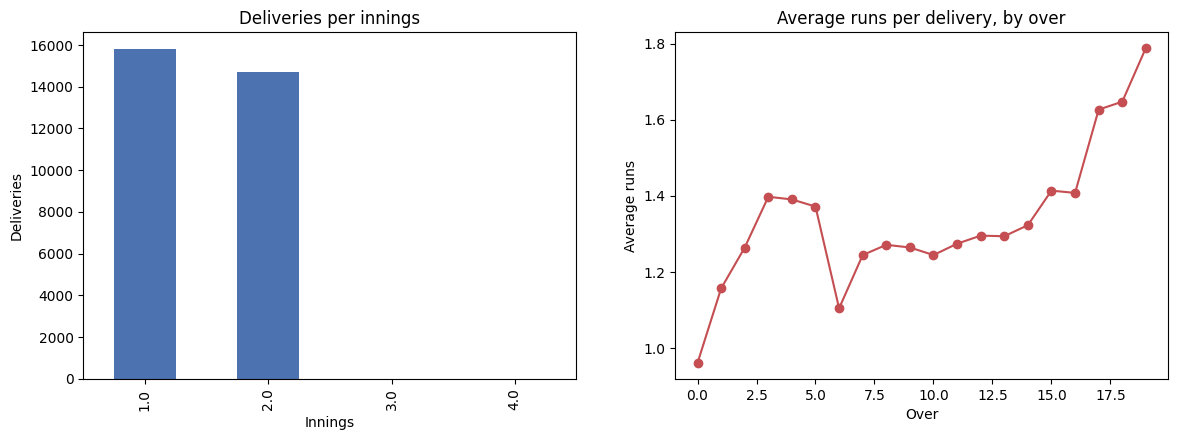

In [134]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
# Deliveries per innings
df_clean["innings"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Deliveries per innings")
axes[0].set_xlabel("Innings")
axes[0].set_ylabel("Deliveries")

# Average runs per delivery by over
(df_clean.groupby("overs")["total_run"].mean()
    .plot(kind="line", marker="o", ax=axes[1], color="#C44E52"))
axes[1].set_title("Average runs per delivery, by over")
axes[1].set_xlabel("Over")
axes[1].set_ylabel("Average runs")

plt.show()

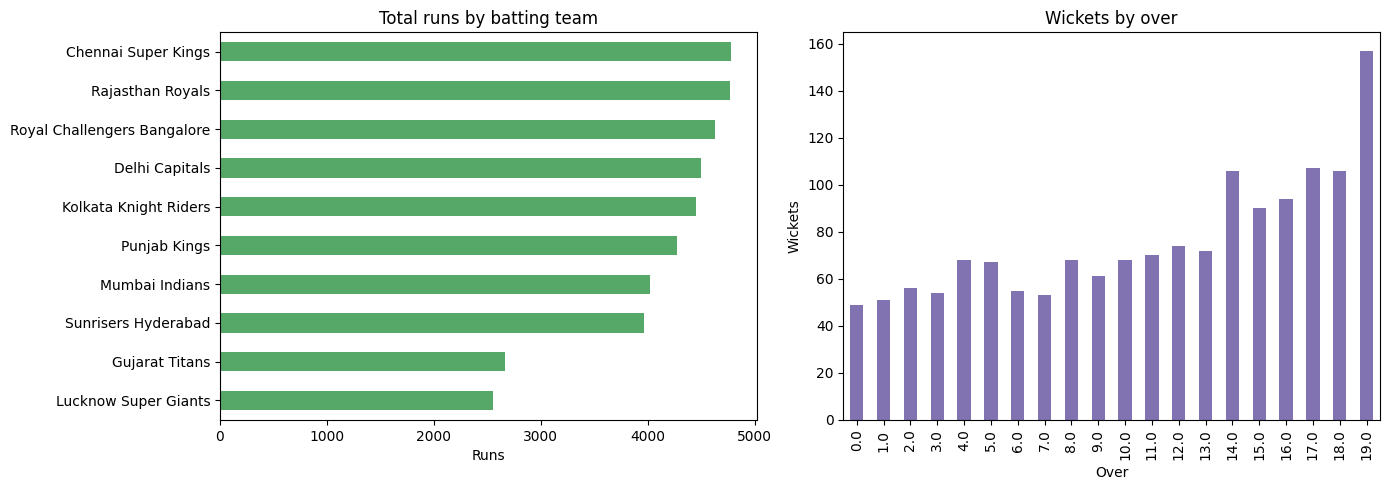

In [135]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Total runs by batting team
(df_clean.groupby("BattingTeam")["total_run"].sum()
    .sort_values().plot(kind="barh", ax=axes[0], color="#55A868"))
axes[0].set_title("Total runs by batting team")
axes[0].set_xlabel("Runs")
axes[0].set_ylabel("")

# Wickets by over
(df_clean.groupby("overs")["isWicketDelivery"].sum()
    .plot(kind="bar", ax=axes[1], color="#8172B2"))
axes[1].set_title("Wickets by over")
axes[1].set_xlabel("Over")
axes[1].set_ylabel("Wickets")

plt.tight_layout()
plt.show()

## 9. Saving the cleaned data


In [138]:
df_clean.to_csv("ipl_deliveries_clean.csv", index=False)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


## 10. Summary

**What I did**
- Loaded and inspected the raw deliveries data (shape, columns, data types, summary statistics)
- Checked missing values and duplicate rows
- Validated innings, overs, ball numbers, the wicket flag, the non-boundary flag and team names
- Checked that `batsman_run + extras_run` matches `total_run` on every delivery
- Stripped extra spaces, removed duplicates and merged renamed team names
- Flagged run mismatches instead of deleting them
- Ran charts to confirm the cleaned data looks sensible
- Saved the result as `ipl_deliveries_clean.csv`

**Next steps**
- Load the clean file into a SQL database and write queries on batters, bowlers, teams and match phases
- Build a Power BI dashboard from those results